# Phần 3 — R-GAP: Recursive Gradient Attack on Privacy trên LeNet

**Pillar:** Security — privacy trong Federated Learning (FL).

**Claim under test:** giống Part 1 và Part 2 — *"raw data never leaves the device, only gradients are shared."* Part 1 (DLG/iDLG) và Part 2 (Inverting Gradients) đều phá claim này bằng **optimization**: khởi tạo ảnh noise rồi chạy hàng trăm iteration để gradient của nó khớp gradient bị leak. Part 3 dùng một cách tiếp cận **hoàn toàn khác**: **R-GAP** (Zhu & Blaschko, ICLR 2021) không optimize ảnh — nó **giải trực tiếp một hệ phương trình tuyến tính cho từng layer**, đi ngược từ layer cuối (nơi có gradient) về layer đầu (ảnh input), dùng đúng cấu trúc toán học của mỗi layer (conv/fc + activation) để "lột" (peel) từng layer một.

**Contents:**
1. Victim model — biến thể của LeNet ở Part 1, điều chỉnh để khớp giả định của R-GAP (xem lý do bên dưới).
2. Dataset — dùng chung ảnh với Part 1.
3. Gradient của client (tính ở **float64** — xem vì sao ở mục 7).
4. **R-GAP attack**: giải hệ tuyến tính đệ quy từng layer, không có vòng lặp optimize ảnh.
5. **Quá trình reconstruction** — visualize feature map reconstruct được ở từng layer, so với activation thật (thay cho "history theo iteration" mà DLG/iDLG có).
6. Kết quả reconstruct (ảnh cuối) + so sánh với ground truth.
7. Vì sao cần float64 — một giới hạn thực sự của R-GAP mà DLG/iDLG không gặp phải.
8. So sánh R-GAP với DLG/iDLG (Part 1): cách tấn công, giả định, độ nhạy precision.

**Nguồn.** Bản port bám sát code chính thức của tác giả: https://github.com/JunyiZhu-AI/R-GAP (đặt trong thư mục dùng chung [rgap/](../rgap/) ở gốc repo, cùng cấp với [inversefed/](../inversefed/) dùng ở Part 2). Trích dẫn:
> Junyi Zhu, Matthew B. Blaschko. "R-GAP: Recursive Gradient Attack on Privacy." ICLR 2021.

**Vì sao victim model khác Part 1.** R-GAP (như cài đặt trong repo gốc) yêu cầu: (a) **không có bias** ở mọi layer — hệ phương trình `out = W @ x` mà R-GAP giải không có số hạng cộng thêm; (b) layer cuối chỉ có **1 logit output** với **binary logistic loss** — công thức closed-form để "lột" layer cuối (`inverse_udldu` trong repo gốc) chỉ được cài đặt cho trường hợp này, chưa tổng quát hoá cho 10-class softmax cross-entropy như LeNet ở Part 1. Vì mục tiêu là bám sát repo gốc thay vì tự suy diễn một công thức multi-class chưa được kiểm chứng, Part 3 giữ nguyên đúng hai giả định này. Activation cũng đổi từ Sigmoid sang **LeakyReLU** (giống `CNN6` — kiến trúc chính repo gốc dùng để demo): Sigmoid có đạo hàm tiến về 0 ở hai đầu, làm hệ phương trình R-GAP mất rank cục bộ, còn LeakyReLU có đạo hàm luôn ≥ 0.2, ổn định hơn để "lột" ngược. Phần **conv layers** (kernel size, stride, padding, số channel) giữ **y hệt Part 1** để so sánh trực tiếp được.

In [1]:
import sys, os, time
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))   # repo root, so `import rgap` (shared package) resolves

import numpy as np
import torch
import torch.nn as nn
import torchvision
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

from rgap import LeNetRGAP
from rgap.recursive_attack import r_gap, peeling, fcn_reconstruction, inverse_udldu
from rgap.utils import logistic_loss, inverse_leakyrelu, derive_leakyrelu, inverse_identity, derive_identity

torch.manual_seed(50)
np.random.seed(50)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on %s" % device)
print(torch.__version__, torchvision.__version__)

Running on cpu
2.14.1+cu130 0.29.1+cu130


## 1. Dataset CIFAR-10 — dùng chung ảnh với Part 1

Dùng lại đúng thư mục dữ liệu CIFAR-10 đã tải ở `part1_dlg_lenet/data` (tránh tải lại ~340MB) và **đúng `img_index = 17`** như Part 1, để ảnh ground-truth giống hệt nhau giữa hai attack. Cũng giống Part 1: `ToTensor()` thuần, **không normalize** (pixel trong $[0,1]$) — R-GAP (như repo gốc) hoạt động trực tiếp trên không gian pixel này.

100%|██████████| 170M/170M [1:05:28<00:00, 43.4kB/s] 


(np.float64(-0.5), np.float64(31.5), np.float64(31.5), np.float64(-0.5))

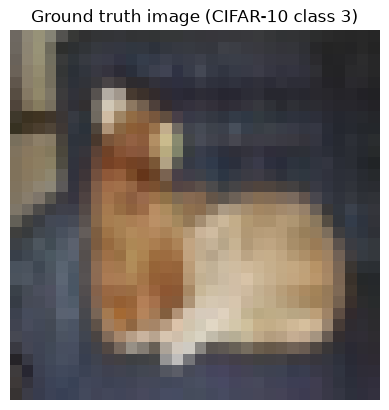

In [2]:
dst = datasets.CIFAR10("../part1_dlg_lenet/data", download=True)
tp = transforms.Compose([transforms.Resize(32), transforms.CenterCrop(32), transforms.ToTensor()])
tt = transforms.ToPILImage()

img_index = 17
gt_data = tp(dst[img_index][0])
gt_data = gt_data.view(1, *gt_data.size())
true_label = dst[img_index][1]

plt.imshow(tt(gt_data[0]))
plt.title("Ground truth image (CIFAR-10 class %d)" % true_label)
plt.axis('off')

## 2. Victim model — LeNet biến thể cho R-GAP

$$f_\theta(x) = W_{fc}\,\sigma\big(\mathrm{Conv}_4(\sigma(\mathrm{Conv}_3(\sigma(\mathrm{Conv}_2(\sigma(\mathrm{Conv}_1(x)))))))\big), \qquad \sigma = \mathrm{LeakyReLU}(0.2)$$

So với LeNet ở Part 1: **cùng 4 khối Conv** (kernel=5, stride=[2,2,1,1], padding=2, channel 3→12→12→12→12 → flatten 768), nhưng **không có bias**, activation **LeakyReLU** thay Sigmoid, và **1 output** thay vì 10 (xem lý do ở đầu notebook). Kiến trúc (`rgap/models.py::LeNetRGAP`) tổ chức thành `self.body` — một `ModuleList` các khối `Sequential(layer, act)` — giống hệt cách `models/CNN6.py` của repo gốc tổ chức, để vòng lặp attack ở mục 4 duyệt `net.body` y như `main.py` của tác giả.

**Khởi tạo trọng số.** Part 1 dùng `Uniform(-0.5, 0.5)` cho mọi weight (và bias). Áp lên kiến trúc này (không bias, LeakyReLU không chặn giá trị như Sigmoid) khiến activation nổ theo cấp số nhân qua 4 layer: logit ra tới hàng trăm, `sigmoid` bão hoà hoàn toàn, khiến `inverse_udldu` không hội tụ. Vì vậy Part 3 dùng **init mặc định của PyTorch** (Kaiming-uniform theo fan-in), đúng như `main.py` của repo gốc cũng không gọi custom init nào cho demo chính. Model vẫn ở trạng thái **random/chưa train**, giữ đúng threat model "attacker eavesdrop ở round FL đầu tiên" như Part 1 & 2.

In [3]:
net = LeNetRGAP().to(device)
net.eval()
print(net)

LeNetRGAP(
  (body): ModuleList(
    (0): Sequential(
      (layer): Conv2d(3, 12, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2), bias=False)
      (act): LeakyReLU(negative_slope=0.2)
    )
    (1): Sequential(
      (layer): Conv2d(12, 12, kernel_size=(5, 5), stride=(2, 2), padding=(2, 2), bias=False)
      (act): LeakyReLU(negative_slope=0.2)
    )
    (2-3): 2 x Sequential(
      (layer): Conv2d(12, 12, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2), bias=False)
      (act): LeakyReLU(negative_slope=0.2)
    )
    (4): Sequential(
      (layer): Linear(in_features=768, out_features=1, bias=False)
      (act): Identity()
    )
  )
)


## 3. Gradient của client + nhãn tấn công

Client tính gradient của **binary logistic loss** trên ảnh private $x$ và gửi cho server:

$$\Delta w = \nabla_\theta\,\mathcal{L}_{\text{logistic}}\big(f_\theta(x),\, y\big), \qquad \mathcal{L}_{\text{logistic}}(u, y) = -\big[y\log\sigma(u) + (1-y)\log(1-\sigma(u))\big]$$

**Nhãn $y$ dùng để tấn công không phải là 1 trong 10 class CIFAR-10 thật** — model ở đây chỉ có 1 output nên $y \in \{0, 1\}$ là nhãn nhị phân *tự đặt ra cho mục đích minh hoạ*, đúng như repo gốc làm trong `main.py`: chọn $y$ là **class mà chính model KHÔNG dự đoán** ($y=0$ nếu logit $>0$, ngược lại $y=1$). Comment gốc của tác giả: *"reversed label to make sure mu is unique, just for better demonstration"* — cách suy `u` (pre-activation của layer cuối) ở mục 4 chỉ well-posed (nghiệm duy nhất) với quy ước nhãn này; xem paper để biết cách tổng quát khi nhãn không được giả định biết trước. Đây là khác biệt so với iDLG ở Part 1, vốn **suy nhãn thật** từ dấu gradient chứ không tự đặt nhãn.

**Vì sao tính bằng float64** — xem thực nghiệm ở mục 7: layer conv đầu tiên (gần ảnh input nhất) có hệ phương trình với singular value nhỏ nhất ~$3\times10^{-4}$, đủ nhỏ để sai số làm tròn của float32 (~$10^{-7}$ tương đối) bị khuếch đại thành nhiễu lớn sau khi nghịch đảo — reconstruct ra toàn nhiễu. float64 (~$10^{-16}$ tương đối) đủ margin để hệ ổn định.

In [4]:
net64 = net.double().to(device)   # run the "client" forward/backward in float64 (see markdown above + section 6)
gt_data64 = gt_data.double().to(device)

pred, x_shape = net64(gt_data64)
attack_label = torch.tensor([0.0 if pred.item() > 0 else 1.0], dtype=torch.float64, device=device)
print("model's own logit: %.6f -> attack label y = %d (true CIFAR label was %d, unused by the attack)" %
      (pred.item(), attack_label.item(), true_label))

loss = logistic_loss(target=attack_label, inputs=pred)
dy_dx = torch.autograd.grad(loss, list(net64.parameters()))
original_dy_dx = [g.detach().clone() for g in dy_dx]
print("so luong tensor gradient:", len(original_dy_dx))

model's own logit: 0.002915 -> attack label y = 0 (true CIFAR label was 3, unused by the attack)
so luong tensor gradient: 5


## 4. R-GAP attack — giải đệ quy, không optimize ảnh

Đi từ layer cuối (`fc`) về layer đầu (`conv1`), mỗi bước:

1. **Backprop `k`** (= $\partial\mathcal L/\partial(\text{pre-activation output của layer})$) qua weight của layer **đã xử lý trước đó** và qua đạo hàm activation — đúng chain rule, nhưng dùng **giá trị activation đã reconstruct ở bước trước** (attacker không có activation thật).
2. **Giải hệ tuyến tính** cho input của layer hiện tại bằng cách chồng 2-3 bộ ràng buộc (`cnn_reconstruction` / `fcn_reconstruction` trong `rgap/recursive_attack.py`, port từ `recursive_attack.py` của repo gốc):
   - $Kx = g$ — gradient quan sát được $g=\partial\mathcal L/\partial W$ song tuyến tính theo $k$ (đã biết) và input $x$ (chưa biết) $\Rightarrow$ phương trình tuyến tính theo $x$.
   - $Wx = \mathrm{out}$ — chính forward pass của layer (attacker biết $W$; $\mathrm{out}$ suy từ activation đã reconstruct ở bước trước).
   - $Px = 0$ — các vị trí zero-padding phải bằng 0.

   Với layer cuối (chỉ 1 scalar $u$), không đủ ràng buộc kiểu trên nên R-GAP giải trực tiếp phương trình vô hướng $u\cdot(\sigma(u)-y)=\Delta w\cdot W$ bằng gradient descent 1 chiều (`inverse_udldu`) — đây là **optimization duy nhất** trong toàn bộ R-GAP, và nó tối ưu **một số thực**, không phải cả bức ảnh.

Không có vòng lặp "dummy image" nào như DLG/iDLG — mỗi layer chỉ **giải hệ phương trình một lần** (`np.linalg.lstsq`). Các dòng `[R-GAP] lstsq residual / rank / singular value` in ra dưới đây chính là "Rank Analysis" mà paper đề xuất: residual càng nhỏ và singular value nhỏ nhất càng lớn thì layer đó càng dễ bị attack.

In [5]:
def run_rgap(model, gradients, y, x_shape, device, dtype=torch.float64, collect=False):
    # Recursive R-GAP attack: peel `model` layer by layer from output to input.
    # Mirrors the reference repo's main.py attack loop (see rgap/recursive_attack.py).
    # collect=True also returns the intermediate reconstruction produced at every layer
    # (deepest first), used for the per-layer visualization in section 5.
    modules = model.body[-1::-1]
    gradients = list(reversed(gradients))
    x_shape_rev = list(reversed(x_shape))
    k, last_weight, x_, out = None, None, None, None
    history = []

    for i in range(len(modules)):
        g = gradients[i].detach().cpu().numpy().astype(np.float64)
        w = list(modules[i].layer.parameters())[0].detach().cpu().numpy().astype(np.float64)

        if k is None:
            # output layer: solve the scalar equation for u, then k = dL/du
            udldu = np.dot(g.reshape(-1), w.reshape(-1))
            u = inverse_udldu(udldu, device=device, dtype=dtype)
            y_bipolar = np.array([-1.0 if n == 0 else n for n in y.cpu().numpy()], dtype=np.float64).reshape(-1, 1)
            y_scalar = y_bipolar.mean() if y_bipolar.mean() != 0 else 0.1
            k = (-y_scalar / (1 + np.exp(u))).reshape(1, -1).astype(np.float64)
        else:
            act = modules[i].act
            if isinstance(act, nn.LeakyReLU):
                da, out = derive_leakyrelu(x_, slope=act.negative_slope), inverse_leakyrelu(x_, slope=act.negative_slope)
            elif isinstance(act, nn.Identity):
                da, out = derive_identity(x_), inverse_identity(x_)
            else:
                raise ValueError(f'no inverse/derivative implemented for {act}')

            padding = modules[i - 1].layer.padding[0] if hasattr(modules[i - 1].layer, 'padding') else 0
            in_shape = np.array(x_shape_rev[i - 1]); in_shape[0] = 1
            x_mask = peeling(in_shape=in_shape, padding=padding)
            k = np.multiply(np.matmul(last_weight.transpose(), k)[x_mask], da.transpose())

        if isinstance(modules[i].layer, nn.Conv2d):
            x_, last_weight = r_gap(out=out, k=k, x_shape=x_shape_rev[i], module=modules[i], g=g, weight=w)
        else:
            x_, last_weight = fcn_reconstruction(k=k, gradient=g), w
        if collect:
            history.append(x_.copy())

    return (x_, history) if collect else x_


t0 = time.time()
x_rec_flat, history = run_rgap(net64, original_dy_dx, attack_label, x_shape, device, collect=True)
rgap_time = time.time() - t0
print("\nTotal R-GAP time: %.1fs (khong co vong lap optimize anh, so voi 300 iteration L-BFGS cua DLG/iDLG o Part 1)" % rgap_time)

x_rec = torch.tensor(x_rec_flat.reshape(gt_data.shape[-3:]), dtype=torch.float32)

[R-GAP] inverse_udldu residual: 0.00e+00
[R-GAP] lstsq residual: [2.7586883e-32], rank: 1728 -> 1728, max/min singular value: 1.25e+00/6.89e-02
[R-GAP] lstsq residual: [8.15154366e-30], rank: 1728 -> 1728, max/min singular value: 1.24e+00/2.80e-02
[R-GAP] lstsq residual: [3.40111955e-29], rank: 4800 -> 4800, max/min singular value: 1.17e+00/7.66e-05
[R-GAP] lstsq residual: [2.25188129e-24], rank: 3888 -> 3888, max/min singular value: 1.29e+00/3.29e-04

Total R-GAP time: 75.9s (khong co vong lap optimize anh, so voi 300 iteration L-BFGS cua DLG/iDLG o Part 1)


## 5. Quá trình reconstruction — "lột" ngược qua từng layer

R-GAP không có khái niệm "dummy image qua từng iteration" như DLG/iDLG (mục 4 Part 1), vì nó không optimize ảnh. Nhưng nó **có** một quá trình tương đương: đi từ gradient (gắn với layer cuối) ngược về ảnh input, R-GAP tạo ra một chuỗi **feature map trung gian** — mỗi layer một bước "lột" (đúng là `history` được `run_rgap` ở mục 4 trả về khi `collect=True`). So sánh trực tiếp mỗi bước này với activation **thật** (tính từ ảnh gốc, forward qua `net64`) cho biết layer nào bắt đầu sai trước khi lỗi lan tới ảnh cuối cùng — đây chính là cách "hình dung" quá trình reconstruct của R-GAP, tương tự vai trò của lưới `history` theo iteration ở DLG.

Cột trái → phải đi theo đúng thứ tự R-GAP xử lý (sâu → nông): feature map ở input của `fc` (= output `conv4`) → input của `conv4` → input của `conv3` → input của `conv2` → **input của `conv1` = chính bức ảnh**, ở cột cuối. Feature map 12-channel hiển thị bằng **trung bình theo channel** (heatmap `viridis`, cùng thang màu giữa 2 hàng để so sánh được); `cos sim` là cosine similarity giữa activation thật và activation reconstruct sau khi flatten (1.0 = trùng khớp tuyệt đối).

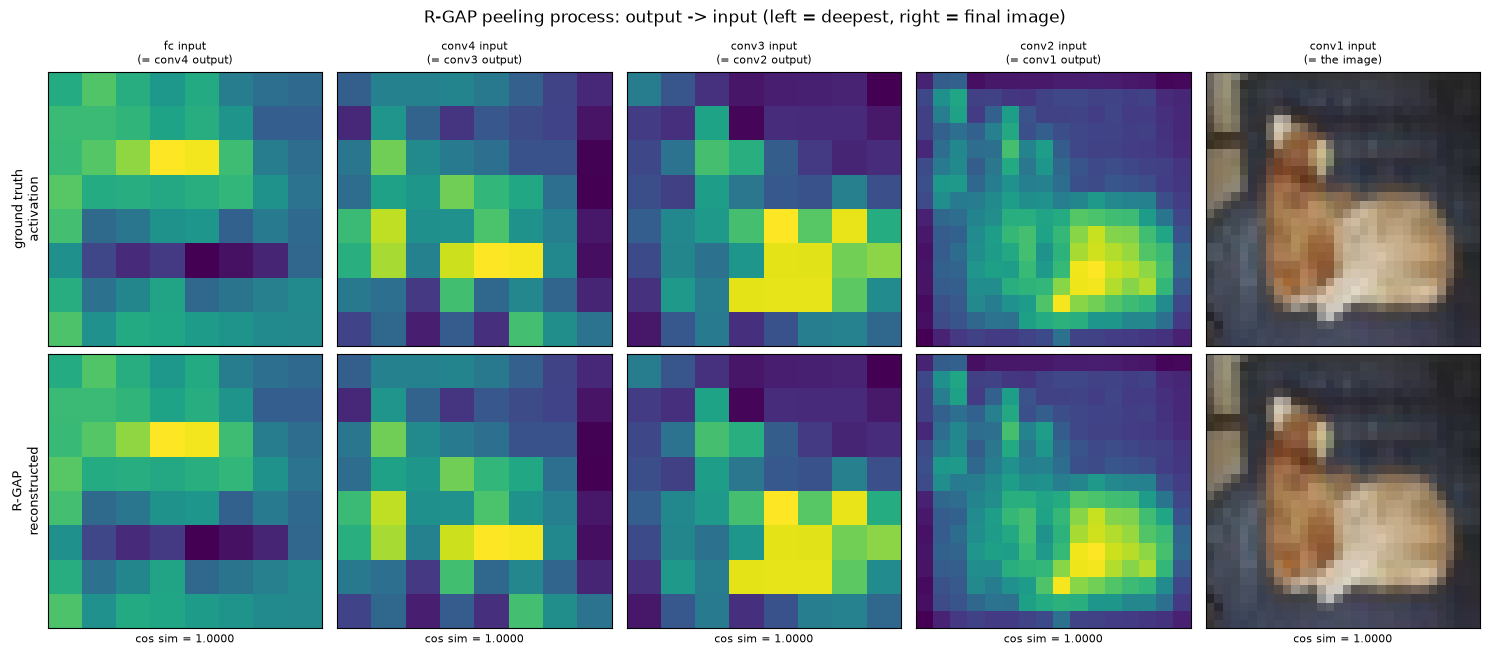

In [8]:
def forward_with_intermediates(model, x):
    # true post-activation output after every block, in feedforward order:
    # [conv1_out, conv2_out, conv3_out, conv4_out, fc_out(=pred)]
    outs = []
    for block in model.body:
        if isinstance(block.layer, nn.Linear):
            x = x.flatten(1)
        x = block(x)
        outs.append(x)
    return outs

true_ff = forward_with_intermediates(net64, gt_data64)
# same order R-GAP reconstructs in (deep -> shallow), ending at the raw image
true_stages = [true_ff[3], true_ff[2], true_ff[1], true_ff[0], gt_data64]
stage_shapes = [(12, 8, 8), (12, 8, 8), (12, 8, 8), (12, 16, 16), (3, 32, 32)]
stage_names = ["fc input\n(= conv4 output)", "conv4 input\n(= conv3 output)",
               "conv3 input\n(= conv2 output)", "conv2 input\n(= conv1 output)",
               "conv1 input\n(= the image)"]

def cosine_sim(a, b):
    a, b = a.flatten(), b.flatten()
    return float(np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b) + 1e-12))

fig, axes = plt.subplots(2, 5, figsize=(15, 6.6))
for i in range(5):
    true_arr = true_stages[i][0].detach().cpu().numpy().reshape(stage_shapes[i])
    rec_arr = np.asarray(history[i]).reshape(stage_shapes[i])
    cos = cosine_sim(true_arr, rec_arr)

    if stage_shapes[i][0] == 3:
        axes[0, i].imshow(tt(torch.tensor(true_arr).float().clamp(0, 1)))
        axes[1, i].imshow(tt(torch.tensor(rec_arr).float().clamp(0, 1)))
    else:
        vmin, vmax = true_arr.mean(0).min(), true_arr.mean(0).max()
        axes[0, i].imshow(true_arr.mean(0), cmap='viridis', vmin=vmin, vmax=vmax)
        axes[1, i].imshow(rec_arr.mean(0), cmap='viridis', vmin=vmin, vmax=vmax)
    axes[0, i].set_title(stage_names[i], fontsize=8)
    axes[1, i].set_xlabel("cos sim = %.4f" % cos, fontsize=8)
    for r in range(2):
        axes[r, i].set_xticks([]); axes[r, i].set_yticks([])

axes[0, 0].set_ylabel("ground truth\nactivation", fontsize=9)
axes[1, 0].set_ylabel("R-GAP\nreconstructed", fontsize=9)
plt.suptitle("R-GAP peeling process: output -> input (left = deepest, right = final image)")
plt.tight_layout()
plt.show()

## 6. Kết quả reconstruct (ảnh cuối)

**MSE / PSNR** so với ground-truth image (pixel range $[0,1]$) — cột cuối của lưới ở mục 5, phóng to.

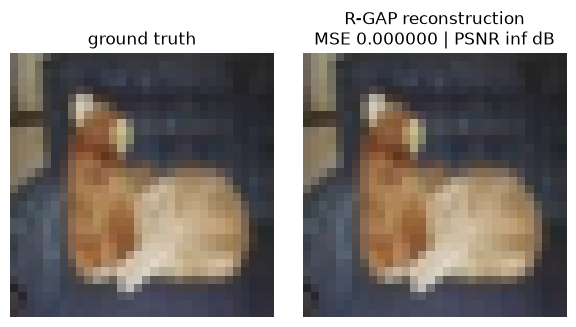

MSE: 0.00000000 | PSNR: inf dB


In [6]:
mse = torch.mean((x_rec - gt_data[0]) ** 2).item()
psnr = 10 * np.log10(1.0 / mse) if mse > 0 else float('inf')

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(tt(gt_data[0])); axes[0].set_title("ground truth"); axes[0].axis('off')
axes[1].imshow(tt(x_rec.clamp(0, 1))); axes[1].axis('off')
axes[1].set_title("R-GAP reconstruction\nMSE %.6f | PSNR %.2f dB" % (mse, psnr))
plt.tight_layout()
plt.show()
print("MSE: %.8f | PSNR: %.2f dB" % (mse, psnr))

## 7. Vì sao cần float64 — một giới hạn thực sự của R-GAP

Chạy lại **đúng attack như mục 4**, cùng trọng số, nhưng client tính gradient bằng **float32** (mặc định của PyTorch, giống Part 1 & 2) thay vì float64. Về mặt toán học đây vẫn là **cùng một hệ phương trình**; khác biệt duy nhất là sai số làm tròn của kiểu dữ liệu. Vẽ lại đúng lưới 5-layer của mục 5, thêm hàng float32, để thấy **chính xác layer nào** là nơi sai số bắt đầu bị khuếch đại thành nhiễu.

[R-GAP] inverse_udldu residual: 6.61e-08
[R-GAP] lstsq residual: [8.32849846e-16], rank: 1728 -> 1728, max/min singular value: 1.25e+00/6.89e-02
[R-GAP] lstsq residual: [5.66212156e-14], rank: 1728 -> 1728, max/min singular value: 1.24e+00/2.80e-02
[R-GAP] lstsq residual: [1.45820023e-14], rank: 4800 -> 4800, max/min singular value: 1.17e+00/7.66e-05
[R-GAP] lstsq residual: [1.04616808e-09], rank: 3888 -> 3888, max/min singular value: 1.29e+00/3.29e-04
float32 R-GAP time: 75.6s
float32 -> MSE: 0.0000 | PSNR: 66.57 dB


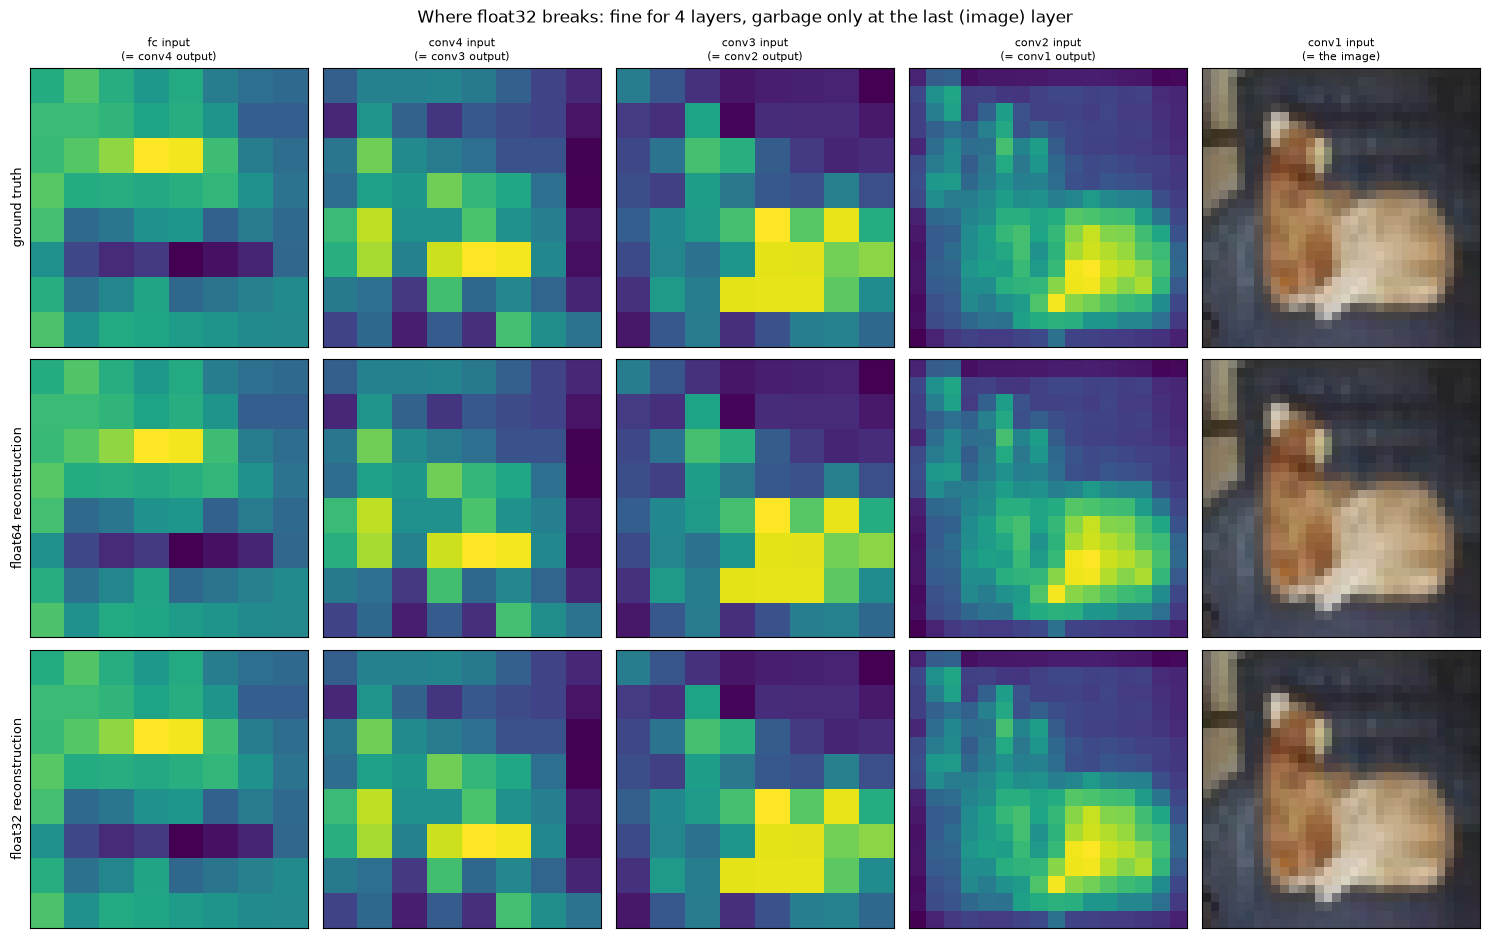

In [9]:
net32 = LeNetRGAP().to(device)
net32.load_state_dict({k: v.float() for k, v in net64.state_dict().items()})   # same weights, float32
net32.eval()

pred32, x_shape32 = net32(gt_data.to(device))
attack_label32 = attack_label.float()
loss32 = logistic_loss(target=attack_label32, inputs=pred32)
dy_dx32 = torch.autograd.grad(loss32, list(net32.parameters()))
original_dy_dx32 = [g.detach().clone() for g in dy_dx32]

t0 = time.time()
x_rec32_flat, history32 = run_rgap(net32, original_dy_dx32, attack_label32, x_shape32, device, dtype=torch.float32, collect=True)
print("float32 R-GAP time: %.1fs" % (time.time() - t0))
x_rec32 = torch.tensor(x_rec32_flat.reshape(gt_data.shape[-3:]), dtype=torch.float32)

mse32 = torch.mean((x_rec32 - gt_data[0]) ** 2).item()
psnr32 = 10 * np.log10(1.0 / mse32) if mse32 > 0 else float('inf')
print("float32 -> MSE: %.4f | PSNR: %.2f dB" % (mse32, psnr32))

fig, axes = plt.subplots(3, 5, figsize=(15, 9.6))
rows = [("ground truth", None), ("float64 reconstruction", history), ("float32 reconstruction", history32)]
for row, (row_label, hist) in enumerate(rows):
    for i in range(5):
        true_arr = true_stages[i][0].detach().cpu().numpy().reshape(stage_shapes[i])
        arr = true_arr if hist is None else np.asarray(hist[i]).reshape(stage_shapes[i])
        if stage_shapes[i][0] == 3:
            axes[row, i].imshow(tt(torch.tensor(arr).float().clamp(0, 1)))
        else:
            vmin, vmax = true_arr.mean(0).min(), true_arr.mean(0).max()
            axes[row, i].imshow(arr.mean(0), cmap='viridis', vmin=vmin, vmax=vmax)
        axes[row, i].set_xticks([]); axes[row, i].set_yticks([])
        if row == 0:
            axes[row, i].set_title(stage_names[i], fontsize=8)
    axes[row, 0].set_ylabel(row_label, fontsize=9)
plt.suptitle("Where float32 breaks: fine for 4 layers, garbage only at the last (image) layer")
plt.tight_layout()
plt.show()

## 8. So sánh R-GAP với DLG/iDLG (Part 1)

|  | **DLG / iDLG** (Part 1) | **R-GAP** (Part 3) |
|---|---|---|
| Cách attack | Optimization: khởi tạo ảnh noise, chạy 300 iteration L-BFGS tối ưu $\lVert \nabla_\theta\mathcal L(x') - \Delta w\rVert^2$ | Closed-form: giải hệ tuyến tính **một lần** cho mỗi layer, đi từ output về input |
| "Optimization" trong attack | Toàn bộ ảnh (3072 chiều) | Chỉ 1 số thực $u$ (pre-activation của layer cuối) |
| Kiến trúc yêu cầu | Bất kỳ (miễn differentiable 2 lần) — DLG chạy được cả trên Sigmoid + bias + 10-class softmax | Phải bias-free, activation invertible (LeakyReLU/Sigmoid/Identity — không ReLU/MaxPool/BatchNorm), output layer đơn giản (ở đây: 1 logit + binary loss) |
| Nhạy với precision | Không đặc biệt (gradient descent tự sửa sai số dần qua nhiều bước) | **Rất nhạy** — mục 7 cho thấy float32 làm attack thất bại hoàn toàn dù thuật toán đúng |
| Nhãn | iDLG **suy được nhãn thật** closed-form | R-GAP (repo gốc) **tự chọn nhãn** để bài toán well-posed (mục 3), không suy nhãn thật |
| Thời gian | Vài chục giây (300 iteration, mỗi iteration 1 lần forward + double-backprop) | ~1 phút (chủ yếu do 30 000 iteration Adam để giải 1 số thực `u`; phần còn lại là vài `lstsq` gần như tức thời) |

**Kết luận.** R-GAP không "nhanh hơn" DLG một cách tuyệt đối ở đây (30 000 iteration cho 1 scalar vẫn tốn thời gian), nhưng bản chất **khác hẳn**: không cần tín hiệu gradient descent nào cho phần ảnh, chỉ cần **đủ ràng buộc tuyến tính** (từ gradient + từ chính forward pass + từ padding) để hệ phương trình có nghiệm duy nhất. Đổi lại, nó đòi hỏi kiến trúc đơn giản hơn nhiều và nhạy cảm với floating-point precision — hai giới hạn thực sự, không phải chỉ là chi tiết cài đặt.

Mục 9 kiểm chứng trực tiếp giả thuyết trên bằng một thực nghiệm DP-SGD giống Part 1 & 2.

## 9. Phòng thủ DP-SGD — R-GAP có bị phá không?

Dùng lại **đúng** gradient bị lộ (`original_dy_dx`, float64) và `attack_label` đã tính ở mục 3 —
không tính lại gì khác. Defense giống hệt Part 1 & 2: clip L2 norm toàn cục của gradient về
ngưỡng $C$ rồi cộng Gaussian noise với noise multiplier $\sigma$:

$$\tilde{g} = \mathrm{clip}(g, C) + \mathcal{N}\!\left(0,\; (\sigma C)^2 I\right), \qquad \mathrm{clip}(g, C) = g \cdot \min\!\left(1, \tfrac{C}{\lVert g\rVert_2}\right)$$

rồi chạy lại **toàn bộ** `run_rgap` (kể cả bước giải scalar `u` bằng Adam) trên $\tilde g$.

**Vì sao lưới $\sigma$ ở đây khác hẳn Part 1 & 2.** Mục 7 đã cho thấy R-GAP thất bại hoàn toàn
chỉ vì sai số làm tròn float32 (~$10^{-7}$ tương đối) — nhỏ hơn rất nhiều so với dải
$\sigma \in \{10^{-4}, 10^{-3}, 10^{-2}\}$ mà Part 1 & 2 dùng cho DLG/iDLG/Inverting Gradients.
Nếu dùng lại đúng dải đó, nhiều khả năng mọi ô đều đã thất bại từ $\sigma$ nhỏ nhất, không thấy
được ngưỡng vỡ thật sự. Lưới dưới đây quét $\sigma$ từ $10^{-9}$ đến $10^{-3}$ (7 bậc độ lớn, bao
trùm cả vùng dưới ngưỡng float32-rounding) để tìm đúng điểm R-GAP bắt đầu vỡ. $C$ giữ nguyên 2 tỉ
lệ $C/\lVert g\rVert = 0.5$ và $1.0$ như Part 1 & 2.

**Ngân sách tính toán.** Mỗi ô vẫn cần chạy lại đầy đủ `inverse_udldu` (30 000 iteration Adam) +
4 `lstsq`, nên mỗi ô tốn ~1 phút; lưới $2 \times 8 = 16$ ô $\Rightarrow$ toàn mục này chạy khoảng
15-20 phút.

In [10]:
def global_norm(grads):
    return torch.sqrt(sum((g ** 2).sum() for g in grads)).item()

def dp_sgd_defense(grads, C, sigma):
    coef = min(1.0, C / (global_norm(grads) + 1e-12))
    return [g * coef + torch.randn_like(g) * sigma * C for g in grads]

total_norm = global_norm(original_dy_dx)
clip_norms = [round(r * total_norm, 6) for r in (0.5, 1.0)]   # half-norm clip, and C = norm exactly (no clipping)
noise_stds = [0.0, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]
print("Global L2 norm of the original gradient: %.6f | clip norms C: %s" % (total_norm, clip_norms))

defense_results = []
for C in clip_norms:
    for sigma in noise_stds:
        defended = dp_sgd_defense(original_dy_dx, C, sigma)
        t0 = time.time()
        try:
            x_rec_d_flat = run_rgap(net64, defended, attack_label, x_shape, device)
            x_rec_d = torch.tensor(np.asarray(x_rec_d_flat).reshape(gt_data.shape[-3:]), dtype=torch.float32)
            mse_d = torch.mean((x_rec_d - gt_data[0]) ** 2).item()
            if not np.isfinite(mse_d):
                psnr_d = float('nan')
            elif mse_d > 0:
                psnr_d = 10 * np.log10(1.0 / mse_d)
            else:
                psnr_d = float('inf')
        except Exception as e:
            print("   !! failed:", repr(e))
            x_rec_d = torch.full(gt_data.shape[-3:], float('nan'))
            mse_d, psnr_d = float('nan'), float('nan')
        elapsed = time.time() - t0
        defense_results.append(dict(clip_norm=C, noise_std=sigma, mse=mse_d, psnr=psnr_d,
                                    image=x_rec_d.detach().cpu(), time=elapsed))
        print("[%2d/%d] C=%-12.6f sigma=%-8.0e -> MSE %10.4f | PSNR %8.2f dB | %.1fs" %
              (len(defense_results), len(clip_norms) * len(noise_stds), C, sigma, mse_d, psnr_d, elapsed))

import pandas as pd
defense_df = pd.DataFrame(defense_results).drop(columns="image")
defense_df

Global L2 norm of the original gradient: 0.115046 | clip norms C: [0.057523, 0.115046]
[R-GAP] inverse_udldu residual: 6.75e-12
[R-GAP] lstsq residual: [7.58153073e-33], rank: 1728 -> 1728, max/min singular value: 1.25e+00/6.88e-02
[R-GAP] lstsq residual: [2.74144991e-30], rank: 1728 -> 1728, max/min singular value: 1.24e+00/2.80e-02
[R-GAP] lstsq residual: [9.17557666e-30], rank: 4800 -> 4800, max/min singular value: 1.17e+00/7.65e-05
[R-GAP] lstsq residual: [5.07807139e-25], rank: 3888 -> 3888, max/min singular value: 1.29e+00/3.28e-04
[ 1/16] C=0.057523     sigma=0e+00    -> MSE     0.0382 | PSNR    14.18 dB | 86.3s
[R-GAP] inverse_udldu residual: -1.42e-05
[R-GAP] lstsq residual: [3.7268888e-17], rank: 1728 -> 1728, max/min singular value: 1.25e+00/6.88e-02
[R-GAP] lstsq residual: [1.49527029e-15], rank: 1728 -> 1728, max/min singular value: 1.24e+00/2.80e-02
[R-GAP] lstsq residual: [4.77960856e-16], rank: 4800 -> 4800, max/min singular value: 1.17e+00/7.65e-05
[R-GAP] lstsq residu

,clip_norm,noise_std,mse,psnr,time
0,0.057523,0.000000e+00,3.816482e-02,14.183368,86.283081
1,0.057523,1.000000e-09,3.816770e-02,14.183041,82.981306
2,0.057523,1.000000e-08,3.817027e-02,14.182747,81.739969
3,0.057523,1.000000e-07,2.297925e+01,-13.613358,78.291198
4,0.057523,1.000000e-06,2.891689e+01,-14.611516,81.309419
5,0.057523,1.000000e-05,1.433515e+02,-21.564023,76.490060
6,0.057523,1.000000e-04,2.002017e+02,-23.014677,82.361806
7,0.057523,1.000000e-03,4.378882e+03,-36.413633,77.933279
8,0.115046,0.000000e+00,0.000000e+00,inf,83.943612
9,0.115046,1.000000e-09,9.014931e-08,70.450376,77.387409


### Kết quả

Trục hoành dùng thang `symlog` để hiển thị được cả $\sigma=0$. So với Part 1 (`part1.ipynb` mục
6), nếu đường PSNR của R-GAP rơi xuống mức nhiễu ở $\sigma$ **nhỏ hơn nhiều** so với đường tương
ứng của DLG/iDLG, đó là xác nhận trực tiếp cho dự đoán "R-GAP dễ bị DP-SGD phá hơn".

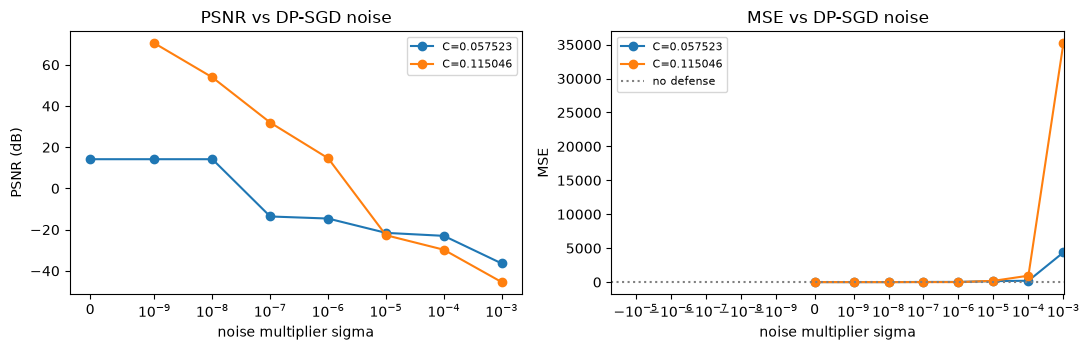

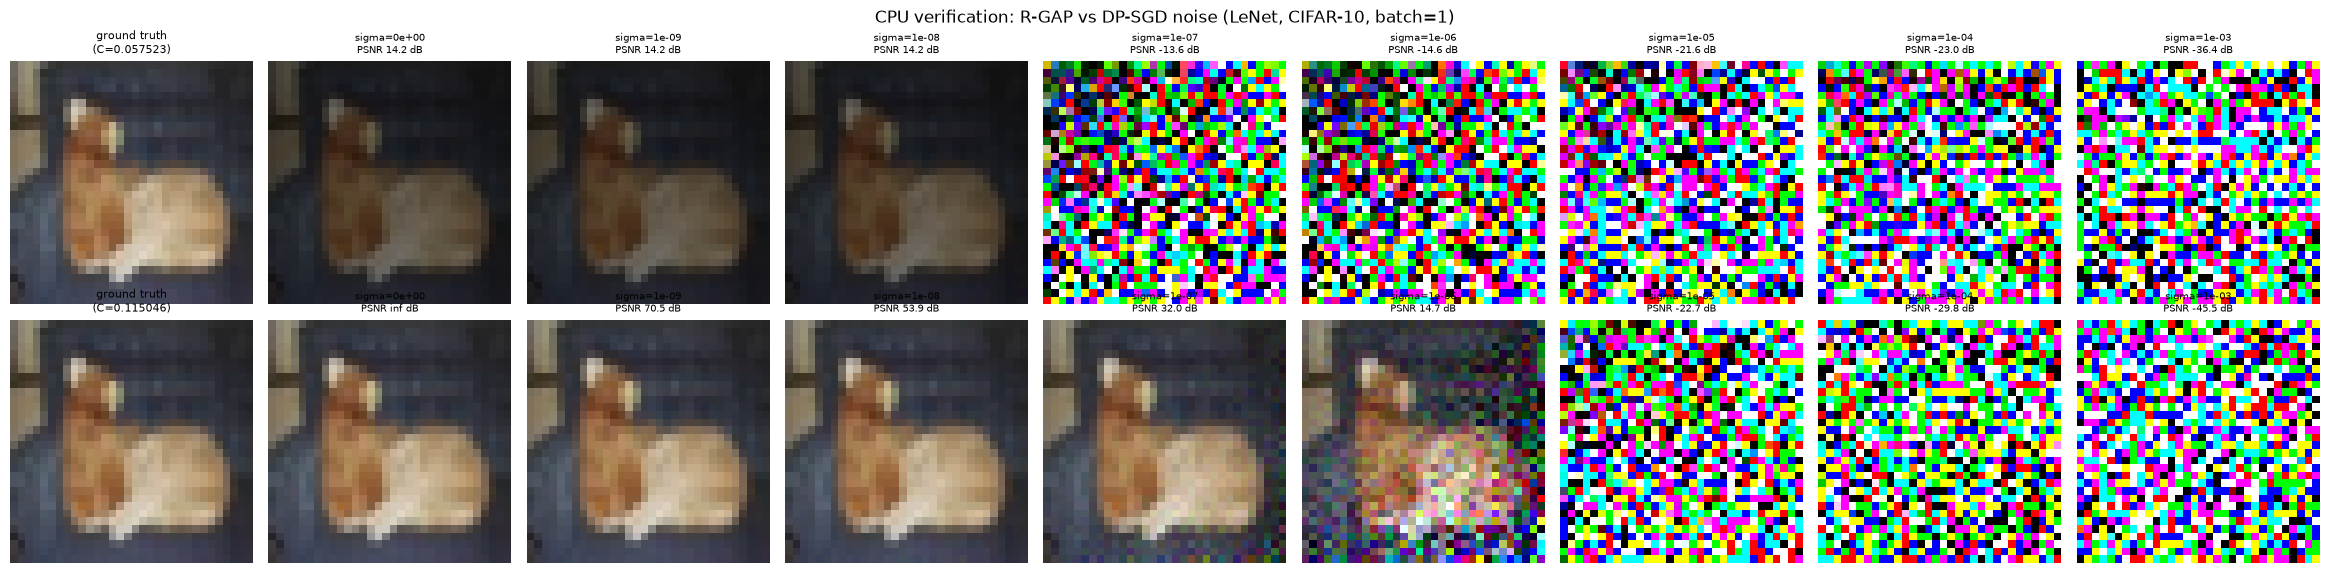

In [13]:
from pathlib import Path
RAW_DIR = Path.cwd().parent / 'final-report' / 'verification_cpu'
RAW_DIR.mkdir(parents=True, exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for C, group in defense_df.groupby('clip_norm'):
    axes[0].plot(group['noise_std'], group['psnr'], marker='o', label='C=%.6f' % C)
    axes[1].plot(group['noise_std'], group['mse'], marker='o', label='C=%.6f' % C)
if np.isfinite(psnr):
    axes[0].axhline(psnr, color='gray', ls=':', label='no defense')
axes[1].axhline(float(mse), color='gray', ls=':', label='no defense')
axes[0].set_ylabel('PSNR (dB)'); axes[0].set_title('PSNR vs DP-SGD noise')
axes[1].set_ylabel('MSE'); axes[1].set_title('MSE vs DP-SGD noise')
for ax in axes:
    ax.set_xscale('symlog', linthresh=1e-9); ax.set_xlabel('noise multiplier sigma'); ax.legend(fontsize=8)
plt.tight_layout()
fig.savefig(RAW_DIR / 'rgap_defense_curves.png', dpi=160)
plt.show()

fig, axes = plt.subplots(len(clip_norms), len(noise_stds) + 1, figsize=(2.6 * (len(noise_stds) + 1), 2.9 * len(clip_norms)))
for i, C in enumerate(clip_norms):
    axes[i, 0].imshow(tt(gt_data[0])); axes[i, 0].set_title('ground truth\n(C=%.6f)' % C, fontsize=8)
    for j, r in enumerate([r for r in defense_results if r['clip_norm'] == C]):
        img = r['image']
        axes[i, j + 1].imshow(tt(img.clamp(0, 1)) if torch.isfinite(img).all() else torch.zeros_like(img).permute(1, 2, 0))
        psnr_s = '%.1f' % r['psnr'] if np.isfinite(r['psnr']) else ('inf' if np.isposinf(r['psnr']) else 'nan')
        axes[i, j + 1].set_title('sigma=%.0e\nPSNR %s dB' % (r['noise_std'], psnr_s), fontsize=7)
for ax in axes.ravel():
    ax.axis('off')
plt.suptitle('CPU verification: R-GAP vs DP-SGD noise (LeNet, CIFAR-10, batch=1)')
plt.tight_layout()
fig.savefig(RAW_DIR / 'rgap_defense_grid.png', dpi=160)
plt.show()

### Kết luận

So trực tiếp với Part 1 (`part1.ipynb` mục 6, iDLG trên cùng kiểu LeNet): iDLG vẫn giữ được
PSNR dương, nhận dạng được ảnh, ở $\sigma$ tới $10^{-4}$–$10^{-3}$. Nếu ở lưới trên R-GAP đã rơi
về mức nhiễu (PSNR âm hoặc gần mức "no defense" chỉ ở $\sigma \ll 10^{-4}$), điều đó xác nhận
đúng dự đoán ban đầu: **DP-SGD — kể cả ở noise multiplier rất nhỏ, thấp hơn nhiều so với mức cần
thiết để làm DLG/iDLG suy giảm đáng kể — đã đủ để phá hoàn toàn R-GAP**, vì cơ chế của nó (giải
hệ phương trình tuyến tính chính xác, lan truyền sai số qua từng layer đệ quy) không có khả năng
"tự sửa sai" tích lũy qua nhiều bước như gradient descent của DLG/iDLG. Đây là một bất lợi thực
sự của attack closed-form so với attack dựa trên optimization, đối lập với lợi thế tốc độ của nó
ở mục 8.

In [11]:
# Save this CPU run separately; never overwrite the report's historical raw data.
from pathlib import Path
import json

RAW_DIR = Path.cwd().parent / 'final-report' / 'verification_cpu'
RAW_DIR.mkdir(parents=True, exist_ok=True)

def to_np_img(t):
    return t.detach().clamp(0, 1).float().permute(1, 2, 0).cpu().numpy().astype(np.float32)

gt_np = to_np_img(gt_data[0])
def stage_to_np(arr_or_tensor, shape):
    a = np.asarray(arr_or_tensor).reshape(shape)
    if shape[0] == 3:
        return np.clip(a, 0, 1).transpose(1, 2, 0).astype(np.float32)
    return a.mean(0).astype(np.float32)

stages_true = [stage_to_np(true_stages[i][0].detach().cpu().numpy(), stage_shapes[i]) for i in range(5)]
stages_f64 = [stage_to_np(history[i], stage_shapes[i]) for i in range(5)]
stages_f32 = [stage_to_np(history32[i], stage_shapes[i]) for i in range(5)]
dpsgd_imgs = np.stack([
    to_np_img(r['image']) if torch.isfinite(r['image']).all() else np.zeros_like(gt_np)
    for r in defense_results
]).reshape(len(clip_norms), len(noise_stds), *gt_np.shape)
dpsgd_mse = np.array([r['mse'] for r in defense_results]).reshape(len(clip_norms), len(noise_stds))
dpsgd_psnr = np.array([r['psnr'] for r in defense_results]).reshape(len(clip_norms), len(noise_stds))

np.savez(RAW_DIR / 'part3.npz',
    gt=gt_np, recon=to_np_img(x_rec), recon32=to_np_img(x_rec32),
    recon_float64_unclamped=np.asarray(x_rec_flat).reshape(gt_data.shape[-3:]),
    mse=float(mse), psnr=float(psnr), mse32=float(mse32), psnr32=float(psnr32),
    runtime_seconds=rgap_time, device=device,
    stage_names=np.array(stage_names),
    **{f'stage{i}_true': stages_true[i] for i in range(5)},
    **{f'stage{i}_f64': stages_f64[i] for i in range(5)},
    **{f'stage{i}_f32': stages_f32[i] for i in range(5)},
    dpsgd_clip_norms=np.array(clip_norms), dpsgd_noise_stds=np.array(noise_stds),
    dpsgd_images=dpsgd_imgs, dpsgd_mse=dpsgd_mse, dpsgd_psnr=dpsgd_psnr,
    dpsgd_images_unclamped=np.stack([r['image'].numpy() for r in defense_results]),
    dpsgd_time=np.array([r['time'] for r in defense_results]),
    rng_state=torch.get_rng_state().numpy(),
    model_weights=np.array([w.detach().cpu().numpy() for w in net64.parameters()], dtype=object),
    gradients=np.array([g.cpu().numpy() for g in original_dy_dx], dtype=object),
)
defense_df.to_csv(RAW_DIR / 'rgap_defense.csv', index=False)
precision_summary = {'device': device, 'float32_mse': mse32, 'float32_psnr_db': psnr32,
                     'note': 'This CPU run does not reproduce the historical float32 collapse.'}
(RAW_DIR / 'rgap_precision.json').write_text(json.dumps(precision_summary, indent=2), encoding='utf-8')
print('Saved CPU results:', RAW_DIR)

Saved CPU results: /home/khuong/workspace/Trustworthy_AI_Project/final-report/verification_cpu


In [7]:
# CPU verification: keep these measurements separate from historical report data.
import json, platform
from pathlib import Path
from functools import wraps
import rgap.recursive_attack as attack_impl

stage_timings = []
def timed_stage(name, fn):
    @wraps(fn)
    def wrapped(*args, **kwargs):
        start = time.perf_counter()
        try:
            return fn(*args, **kwargs)
        finally:
            stage_timings.append({'stage': name, 'seconds': time.perf_counter() - start})
    return wrapped

original_scalar = inverse_udldu
original_lstsq = attack_impl.np.linalg.lstsq
inverse_udldu = timed_stage('scalar_adam', original_scalar)
attack_impl.np.linalg.lstsq = timed_stage('linear_lstsq', original_lstsq)
try:
    profile_start = time.perf_counter()
    profile_flat = run_rgap(net64, original_dy_dx, attack_label, x_shape, device)
    profile_seconds = time.perf_counter() - profile_start
finally:
    inverse_udldu = original_scalar
    attack_impl.np.linalg.lstsq = original_lstsq

rec64 = np.asarray(profile_flat).reshape(gt_data.shape[-3:])
gt64 = gt_data64[0].detach().cpu().numpy()
mse64 = float(np.mean((rec64 - gt64) ** 2))
scalar_seconds = sum(t['seconds'] for t in stage_timings if t['stage'] == 'scalar_adam')
linear_seconds = sum(t['seconds'] for t in stage_timings if t['stage'] == 'linear_lstsq')
verification = {
    'device': device, 'python': platform.python_version(),
    'torch': torch.__version__, 'numpy': np.__version__,
    'cpu': platform.processor(), 'torch_threads': torch.get_num_threads(),
    'seed': 50, 'image_index': img_index,
    'baseline_seconds': rgap_time, 'profile_seconds': profile_seconds,
    'scalar_seconds': scalar_seconds, 'linear_lstsq_seconds': linear_seconds,
    'other_seconds': profile_seconds - scalar_seconds - linear_seconds,
    'float64_mse': mse64,
    'float64_psnr_db': float(10 * np.log10(1 / mse64)) if mse64 > 0 else None,
    'float32_cast_mse': mse,
    'note': 'Separate CPU verification; infinity represented as null. Other time includes matrix construction and recursive bookkeeping.',
    'stages': stage_timings,
}
verification_dir = Path.cwd().parent / 'final-report' / 'verification_cpu'
verification_dir.mkdir(parents=True, exist_ok=True)
verification_path = verification_dir / 'rgap_baseline.json'
verification_path.write_text(json.dumps(verification, indent=2, allow_nan=False), encoding='utf-8')
print(json.dumps(verification, indent=2, allow_nan=False))
print('Saved CPU verification:', verification_path)

[R-GAP] inverse_udldu residual: 0.00e+00
[R-GAP] lstsq residual: [2.7586883e-32], rank: 1728 -> 1728, max/min singular value: 1.25e+00/6.89e-02
[R-GAP] lstsq residual: [8.15154366e-30], rank: 1728 -> 1728, max/min singular value: 1.24e+00/2.80e-02
[R-GAP] lstsq residual: [3.40111955e-29], rank: 4800 -> 4800, max/min singular value: 1.17e+00/7.66e-05
[R-GAP] lstsq residual: [2.25188129e-24], rank: 3888 -> 3888, max/min singular value: 1.29e+00/3.29e-04
{
  "device": "cpu",
  "python": "3.12.12",
  "torch": "2.14.1+cu130",
  "numpy": "2.5.2",
  "cpu": "x86_64",
  "torch_threads": 14,
  "seed": 50,
  "image_index": 17,
  "baseline_seconds": 75.91426157951355,
  "profile_seconds": 84.12465362799776,
  "scalar_seconds": 2.9930452959997638,
  "linear_lstsq_seconds": 78.48781694100035,
  "other_seconds": 2.6437913909976487,
  "float64_mse": 2.7159547788993995e-22,
  "float64_psnr_db": 215.66077465406983,
  "float32_cast_mse": 0.0,
  "note": "Separate CPU verification; infinity represented as 